In [1]:
# CELL 1: Imports Required Libraries

import numpy as np
import pandas as pd
import requests
import warnings

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    mean_absolute_error, mean_squared_error, r2_score
)

import tensorflow as tf
from tensorflow.keras import layers, models

from IPython.display import display

# Cleaning notebook output 
warnings.filterwarnings("ignore", category=UserWarning)

# Fix for NumPy future warning 
if not hasattr(np, "object"):
    np.object = object


C:\Users\Sudip\anaconda3\envs\aiX\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [2]:
# CELL 2: Data loading

#url = "https://huggingface.co/datasets/brandonyeequon/stock-market-data-warehouse/raw/main/15_min_interval_stocks/Consumer_Discretionary/AAP.csv"

file_name = "AAP.csv"   

print("Loading dataset from local file...")
df = pd.read_csv(file_name)

display(df.head())
print("Raw shape:", df.shape)


Loading dataset from local file...


,timestamp,open,high,low,close,volume
0,2001-11-29 09:30:00,11.5629,11.5629,11.5629,11.5629,8099
1,2001-11-29 09:45:00,11.5629,11.5773,11.5485,11.5773,5699
2,2001-11-29 10:00:00,11.5917,11.7067,11.5917,11.7067,23099
3,2001-11-29 10:15:00,11.7643,12.0634,11.7643,12.0634,43499
4,2001-11-29 10:30:00,12.0663,12.0663,12.0634,12.0663,9899


Raw shape: (170106, 6)


In [3]:
# Filter by date range

df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)


START_DATE = None  # e.g. "2019-01-01"
END_DATE   = None  # e.g. "2021-12-31"

if START_DATE:
    df = df[df["timestamp"] >= pd.to_datetime(START_DATE)]
if END_DATE:
    df = df[df["timestamp"] <= pd.to_datetime(END_DATE)]

df = df.reset_index(drop=True)

print("After filtering shape:", df.shape)
display(df.head())


After filtering shape: (170106, 6)


,timestamp,open,high,low,close,volume
0,2001-11-29 09:30:00,11.5629,11.5629,11.5629,11.5629,8099
1,2001-11-29 09:45:00,11.5629,11.5773,11.5485,11.5773,5699
2,2001-11-29 10:00:00,11.5917,11.7067,11.5917,11.7067,23099
3,2001-11-29 10:15:00,11.7643,12.0634,11.7643,12.0634,43499
4,2001-11-29 10:30:00,12.0663,12.0663,12.0634,12.0663,9899


In [4]:
# Feature engineering

# Ensure numeric OHLCV
for c in ["open", "high", "low", "close", "volume"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Remove duplicates
df = df.drop_duplicates(subset=["timestamp"], keep="last").reset_index(drop=True)

def compute_rsi(series, period=14):
    delta = series.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.rolling(period).mean()
    avg_loss = loss.rolling(period).mean()
    rs = avg_gain / (avg_loss + 1e-9)
    return 100 - (100 / (1 + rs))

# Returns
df["return_1"] = df["close"].pct_change()

# Moving averages
df["sma_10"] = df["close"].rolling(10).mean()
df["sma_20"] = df["close"].rolling(20).mean()

# EMA + MACD
df["ema_12"] = df["close"].ewm(span=12, adjust=False).mean()
df["ema_26"] = df["close"].ewm(span=26, adjust=False).mean()
df["macd"] = df["ema_12"] - df["ema_26"]

# Volatility
df["volatility_20"] = df["return_1"].rolling(20).std()

# RSI
df["rsi_14"] = compute_rsi(df["close"], 14)

# ATR
high_low = df["high"] - df["low"]
high_close = (df["high"] - df["close"].shift()).abs()
low_close = (df["low"] - df["close"].shift()).abs()
df["atr_14"] = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1).rolling(14).mean()

# Lag features (intraday useful)
for lag in [1, 2, 3, 6, 12]:
    df[f"close_lag_{lag}"] = df["close"].shift(lag)
    df[f"return_lag_{lag}"] = df["return_1"].shift(lag)

# Time features
df["hour"] = df["timestamp"].dt.hour
df["dayofweek"] = df["timestamp"].dt.dayofweek

print("Feature engineering done.")
display(df.head())


Feature engineering done.


,timestamp,open,high,low,close,volume,return_1,sma_10,sma_20,ema_12,...,close_lag_2,return_lag_2,close_lag_3,return_lag_3,close_lag_6,return_lag_6,close_lag_12,return_lag_12,hour,dayofweek
0,2001-11-29 09:30:00,11.5629,11.5629,11.5629,11.5629,8099,NaN,NaN,NaN,11.562900,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9,3
1,2001-11-29 09:45:00,11.5629,11.5773,11.5485,11.5773,5699,0.001245,NaN,NaN,11.565115,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9,3
2,2001-11-29 10:00:00,11.5917,11.7067,11.5917,11.7067,23099,0.011177,NaN,NaN,11.586898,...,11.5629,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,3
3,2001-11-29 10:15:00,11.7643,12.0634,11.7643,12.0634,43499,0.030470,NaN,NaN,11.660206,...,11.5773,0.001245,11.5629,NaN,NaN,NaN,NaN,NaN,10,3
4,2001-11-29 10:30:00,12.0663,12.0663,12.0634,12.0663,9899,0.000240,NaN,NaN,11.722682,...,11.7067,0.011177,11.5773,0.001245,NaN,NaN,NaN,NaN,10,3


In [5]:

#  Missing value handling

before = len(df)
df = df.dropna().reset_index(drop=True)
after = len(df)

print(f"Dropped rows with NaN: {before - after}")
print("Current shape:", df.shape)


Dropped rows with NaN: 20
Current shape: (170086, 27)


In [6]:
# CELL 6: Feature-target definition
# y_cls = direction (UP=1, DOWN=0)
# y_reg = next close price (regression)


HORIZON = 1  # next 15-min candle

df["y_reg"] = df["close"].shift(-HORIZON)
df["y_cls"] = (df["close"].shift(-HORIZON) > df["close"]).astype(int)

df = df.dropna().reset_index(drop=True)

FEATURES = [c for c in df.columns if c not in ["timestamp", "y_reg", "y_cls"]]

X = df[FEATURES]
y_cls = df["y_cls"]
y_reg = df["y_reg"]

print("Total features:", len(FEATURES))
print("Class distribution:\n", y_cls.value_counts())


Total features: 26
Class distribution:
 y_cls
0    89447
1    80638
Name: count, dtype: int64


In [7]:
#   Train-test split (time-series safe, no shuffle)


split = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_cls_train, y_cls_test = y_cls.iloc[:split], y_cls.iloc[split:]
y_reg_train, y_reg_test = y_reg.iloc[:split], y_reg.iloc[split:]

print("Train size:", len(X_train))
print("Test size :", len(X_test))


Train size: 136068
Test size : 34017


In [8]:
#  Logistic Regression (UP/DOWN Classification)



scaler_cls = StandardScaler()
X_train_scaled = scaler_cls.fit_transform(X_train)
X_test_scaled = scaler_cls.transform(X_test)

lr_model = LogisticRegression(max_iter=2000)
lr_model.fit(X_train_scaled, y_cls_train)

lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression trained.")


Logistic Regression trained.


In [9]:
#  Linear Regression (Next Close Prediction)


# note: scale regression features too (helps linear regression)
scaler_reg = StandardScaler()
X_train_scaled_reg = scaler_reg.fit_transform(X_train)
X_test_scaled_reg = scaler_reg.transform(X_test)

lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled_reg, y_reg_train)

lin_pred_close = lin_reg.predict(X_test_scaled_reg)

print("Linear Regression trained.")


Linear Regression trained.


In [10]:
# Decision Tree (Next Close Prediction)


dt_reg = DecisionTreeRegressor(random_state=42, max_depth=12)
dt_reg.fit(X_train, y_reg_train)

dt_pred_close = dt_reg.predict(X_test)

print("Decision Tree Regressor trained.")


Decision Tree Regressor trained.


In [11]:
# Random Forest
# - Classifier: Prob_UP / Direction
# - Regressor : Pred_Next_Close


rf_model = RandomForestClassifier(
    n_estimators=400,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_cls_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_reg = RandomForestRegressor(
    n_estimators=400,
    random_state=42,
    n_jobs=-1
)
rf_reg.fit(X_train, y_reg_train)

rf_pred_close = rf_reg.predict(X_test)

print("Random Forest classifier + regressor trained.")


Random Forest classifier + regressor trained.


In [12]:
# LSTM (Classification + Regression)


WINDOW = 32  # how many past candles LSTM uses

# LSTM needs scaled features
scaler_lstm = StandardScaler()
X_all_scaled = scaler_lstm.fit_transform(X.values)

def make_sequences(X_scaled, y_arr, window):
    Xs, ys = [], []
    for i in range(window, len(X_scaled)):
        Xs.append(X_scaled[i-window:i])
        ys.append(y_arr[i])
    return np.array(Xs), np.array(ys)

# sequences for classification & regression
X_seq_cls, y_seq_cls = make_sequences(X_all_scaled, y_cls.values, WINDOW)
X_seq_reg, y_seq_reg = make_sequences(X_all_scaled, y_reg.values, WINDOW)

seq_split = int(len(X_seq_cls) * 0.8)

X_seq_train_cls, X_seq_test_cls = X_seq_cls[:seq_split], X_seq_cls[seq_split:]
y_seq_train_cls, y_seq_test_cls = y_seq_cls[:seq_split], y_seq_cls[seq_split:]

X_seq_train_reg, X_seq_test_reg = X_seq_reg[:seq_split], X_seq_reg[seq_split:]
y_seq_train_reg, y_seq_test_reg = y_seq_reg[:seq_split], y_seq_reg[seq_split:]

# ---- LSTM Classifier ----
lstm_clf = models.Sequential([
    layers.Input(shape=(WINDOW, X_seq_cls.shape[2])),
    layers.LSTM(64),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])
lstm_clf.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
lstm_clf.fit(X_seq_train_cls, y_seq_train_cls, epochs=5, batch_size=256, verbose=0)

lstm_prob = lstm_clf.predict(X_seq_test_cls, verbose=0).flatten()
lstm_pred = (lstm_prob >= 0.5).astype(int)

# ---- LSTM Regressor ----
lstm_reg = models.Sequential([
    layers.Input(shape=(WINDOW, X_seq_reg.shape[2])),
    layers.LSTM(64),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])
lstm_reg.compile(optimizer="adam", loss="mse")
lstm_reg.fit(X_seq_train_reg, y_seq_train_reg, epochs=5, batch_size=256, verbose=0)

lstm_pred_close = lstm_reg.predict(X_seq_test_reg, verbose=0).flatten()

print("LSTM classifier + regressor trained.")


LSTM classifier + regressor trained.


In [13]:
#  Comparison
# - Classification metrics (LR, RF, LSTM)
# - Regression metrics (LinearReg, DecisionTree, RF, LSTM)


def cls_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0)
    }

def reg_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

# Classification results
cls_results = pd.DataFrame([
    {"Model": "Logistic Regression", **cls_metrics(y_cls_test, lr_pred)},
    {"Model": "Random Forest",       **cls_metrics(y_cls_test, rf_pred)},
    {"Model": "LSTM",                **cls_metrics(y_seq_test_cls, lstm_pred)}
]).set_index("Model").round(4)

print("\n=== CLASSIFICATION COMPARISON (UP/DOWN) ===")
display(cls_results)

# Regression results
reg_results = pd.DataFrame([
    {"Model": "Linear Regression",   **reg_metrics(y_reg_test, lin_pred_close)},
    {"Model": "Decision Tree",       **reg_metrics(y_reg_test, dt_pred_close)},
    {"Model": "Random Forest",       **reg_metrics(y_reg_test, rf_pred_close)},
    {"Model": "LSTM",                **reg_metrics(y_seq_test_reg, lstm_pred_close)}
]).set_index("Model").round(4)

print("\n=== REGRESSION COMPARISON (NEXT CLOSE) ===")
display(reg_results)



=== CLASSIFICATION COMPARISON (UP/DOWN) ===


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.5340,0.5184,0.2445,0.3323
Random Forest,0.5361,0.5191,0.2961,0.3771
LSTM,0.5169,0.4780,0.2041,0.2860



=== REGRESSION COMPARISON (NEXT CLOSE) ===


,MAE,RMSE,R2
Model,,,
Linear Regression,0.3130,0.5589,0.9999
Decision Tree,4.3858,10.4460,0.9712
Random Forest,4.4719,10.6825,0.9698
LSTM,7.0860,14.8251,0.9419


In [14]:
# CELL 14: Confusion Matrices


cm_lr = confusion_matrix(y_cls_test, lr_pred)
cm_rf = confusion_matrix(y_cls_test, rf_pred)
cm_lstm = confusion_matrix(y_seq_test_cls, lstm_pred)

print("=========== CONFUSION MATRICES (ALL MODELS) ===========")
print("Logistic Regression:\n", cm_lr)
print("\nRandom Forest:\n", cm_rf)
print("\nLSTM:\n", cm_lstm)
print("=======================================================")


=========== CONFUSION MATRICES (ALL MODELS) ===========
Logistic Regression:
 [[14220  3665]
 [12187  3945]]

Random Forest:
 [[13460  4425]
 [11355  4777]]

LSTM:
 [[14289  3594]
 [12837  3291]]


In [15]:
#  Classification Reports


print("\n--- Logistic Regression Report ---")
print(classification_report(y_cls_test, lr_pred))

print("\n--- Random Forest Report ---")
print(classification_report(y_cls_test, rf_pred))

print("\n--- LSTM Report ---")
print(classification_report(y_seq_test_cls, lstm_pred))



--- Logistic Regression Report ---
              precision    recall  f1-score   support

           0       0.54      0.80      0.64     17885
           1       0.52      0.24      0.33     16132

    accuracy                           0.53     34017
   macro avg       0.53      0.52      0.49     34017
weighted avg       0.53      0.53      0.50     34017


--- Random Forest Report ---
              precision    recall  f1-score   support

           0       0.54      0.75      0.63     17885
           1       0.52      0.30      0.38     16132

    accuracy                           0.54     34017
   macro avg       0.53      0.52      0.50     34017
weighted avg       0.53      0.54      0.51     34017


--- LSTM Report ---
              precision    recall  f1-score   support

           0       0.53      0.80      0.63     17883
           1       0.48      0.20      0.29     16128

    accuracy                           0.52     34011
   macro avg       0.50      0.50      0.

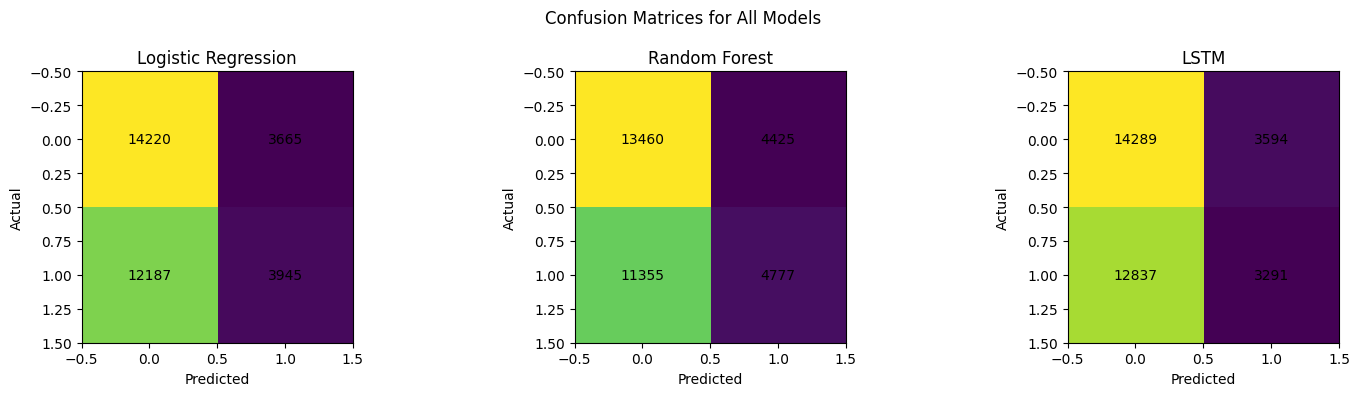

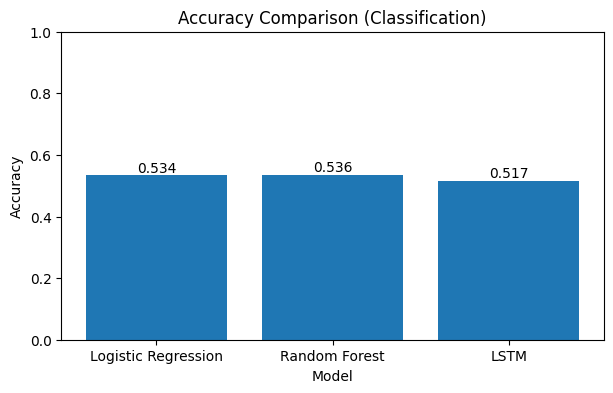

In [16]:
#  Visualization

# 1) Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
models_names = ["Logistic Regression", "Random Forest", "LSTM"]
cms = [cm_lr, cm_rf, cm_lstm]

for ax, name, cm in zip(axes, models_names, cms):
    ax.imshow(cm)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center")

plt.suptitle("Confusion Matrices for All Models")
plt.tight_layout()
plt.show()

# 2) Accuracy comparison bar chart
plt.figure(figsize=(7, 4))
plt.bar(cls_results.index, cls_results["Accuracy"])
plt.title("Accuracy Comparison (Classification)")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
for i, v in enumerate(cls_results["Accuracy"]):
    plt.text(i, v + 0.01, round(float(v), 3), ha="center")
plt.show()


In [17]:

#  Make Prediction on Test Set (Sample Output)


comparison_df = pd.DataFrame({
    "Actual Direction": y_cls_test.values[:10],
    "LR Prediction": lr_pred[:10],
    "RF Prediction": rf_pred[:10]
})

display(comparison_df)


,Actual Direction,LR Prediction,RF Prediction
0,1,1,0
1,1,0,1
2,0,0,0
3,0,0,0
4,1,1,0
5,1,0,0
6,1,0,1
7,1,0,0
8,0,0,1
9,0,0,0


In [18]:

#  Prediction Helpers


def get_row_at_or_before(timestamp):
    subset = df[df["timestamp"] <= timestamp]
    if len(subset) == 0:
        return None
    return subset.iloc[-1]

def trading_signal(prob_up, expected_return,
                   p_buy=0.55, p_sell=0.45,
                   r_buy=0.001, r_sell=-0.001):
    if prob_up >= p_buy and expected_return >= r_buy:
        return "BUY"
    if prob_up <= p_sell and expected_return <= r_sell:
        return "SELL"
    return "HOLD"


In [19]:

# Logistic Regression Prediction (NO signal, NO next close)


def predict_lr(timestamp_str):
    ts = pd.to_datetime(timestamp_str)
    row = get_row_at_or_before(ts)
    if row is None:
        print("No data for this timestamp.")
        return

    X_row = pd.DataFrame([row[FEATURES]], columns=FEATURES)
    X_row_scaled = scaler_cls.transform(X_row)

    prob_up = lr_model.predict_proba(X_row_scaled)[0][1]
    direction = "UP" if prob_up >= 0.5 else "DOWN"

    table = pd.DataFrame([{
        "Model": "Logistic Regression",
        "Prob_UP": round(prob_up, 4),
        "Prob_DOWN": round(1 - prob_up, 4),
        "Direction": direction
    }])

    print("\n=== LR Prediction ===")
    print("Timestamp:", ts, "| Close:", round(float(row["close"]), 4))
    display(table)


In [20]:
# Random Forest Prediction (with next close + signal)

def predict_rf(timestamp_str):
    ts = pd.to_datetime(timestamp_str)
    row = get_row_at_or_before(ts)
    if row is None:
        print("No data for this timestamp.")
        return

    X_row = pd.DataFrame([row[FEATURES]], columns=FEATURES)
    current_close = float(row["close"])

    prob_up = rf_model.predict_proba(X_row)[0][1]
    direction = "UP" if prob_up >= 0.5 else "DOWN"

    next_close = float(rf_reg.predict(X_row)[0])
    exp_ret = (next_close - current_close) / current_close
    sig = trading_signal(prob_up, exp_ret)

    table = pd.DataFrame([{
        "Model": "Random Forest",
        "Prob_UP": round(prob_up, 4),
        "Prob_DOWN": round(1 - prob_up, 4),
        "Direction": direction,
        "Pred_Next_Close": round(next_close, 4),
        "Signal": sig
    }])

    print("\n=== RF Prediction ===")
    print("Timestamp:", ts, "| Close:", round(current_close, 4))
    display(table)


In [21]:
# LSTM Prediction (with next close + signal)

def predict_lstm(timestamp_str):
    ts = pd.to_datetime(timestamp_str)
    row = get_row_at_or_before(ts)
    if row is None:
        print("No data for this timestamp.")
        return

    idx = int(row.name)
    current_close = float(row["close"])

    if idx < WINDOW:
        print("Not enough history for LSTM at this timestamp.")
        return

    X_scaled_all = scaler_lstm.transform(X.values)
    seq = X_scaled_all[idx - WINDOW: idx].reshape(1, WINDOW, -1)

    prob_up = float(lstm_clf.predict(seq, verbose=0)[0][0])
    direction = "UP" if prob_up >= 0.5 else "DOWN"

    next_close = float(lstm_reg.predict(seq, verbose=0)[0][0])
    exp_ret = (next_close - current_close) / current_close
    sig = trading_signal(prob_up, exp_ret)

    table = pd.DataFrame([{
        "Model": "LSTM",
        "Prob_UP": round(prob_up, 4),
        "Prob_DOWN": round(1 - prob_up, 4),
        "Direction": direction,
        "Pred_Next_Close": round(next_close, 4),
        "Signal": sig
    }])

    print("\n=== LSTM Prediction ===")
    print("Timestamp:", ts, "| Close:", round(current_close, 4))
    display(table)


In [22]:
# User Input Prediction (Enter Date-Time)

# This cell allows the user to enter a timestamp manually


user_timestamp = input(
    "Enter timestamp (YYYY-MM-DD HH:MM:SS), e.g. 2020-01-02 10:30:00 : "
)

print("\nRunning predictions for:", user_timestamp)

# Logistic Regression (classification only)
predict_lr(user_timestamp)

# Random Forest (classification + regression + signal)
predict_rf(user_timestamp)

# LSTM (classification + regression + signal)
predict_lstm(user_timestamp)


Enter timestamp (YYYY-MM-DD HH:MM:SS), e.g. 2020-01-02 10:30:00 :  2004-04-25 19:15:11



Running predictions for: 2004-04-25 19:15:11

=== LR Prediction ===
Timestamp: 2004-04-25 19:15:11 | Close: 25.4442


,Model,Prob_UP,Prob_DOWN,Direction
0,Logistic Regression,0.4465,0.5535,DOWN



=== RF Prediction ===
Timestamp: 2004-04-25 19:15:11 | Close: 25.4442


,Model,Prob_UP,Prob_DOWN,Direction,Pred_Next_Close,Signal
0,Random Forest,0.1525,0.8475,DOWN,25.4322,HOLD



=== LSTM Prediction ===
Timestamp: 2004-04-25 19:15:11 | Close: 25.4442


,Model,Prob_UP,Prob_DOWN,Direction,Pred_Next_Close,Signal
0,LSTM,0.4769,0.5231,DOWN,25.0696,HOLD
